<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/_banners/opim5512_banner.svg" alt="OPIM 5512 banner" width="100%">

# Lab 6B · How Sure Is Your Model? Low, Expected and High
### A random forest's spread vs a quantile forest, judged by CRPS

*Lab 6, notebook 2 of 3 · Colab · the same Bradley weather and Connecticut load as Lab 5*

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/drdave-teaching/OPIM5512-notebooks/blob/main/Module4/Lab6B_Model_Uncertainty_RF_vs_QRF.ipynb)

In 6A you saw that **weather error** moves your load forecast. But even with **perfect** weather your model misses (your
Lab 5 test MAE). This notebook makes the model say **how sure it is**: three numbers per hour instead of one.

- **low**: the load should fall **below** this only about **1 hour in 10** (the 10th percentile)
- **expected**: the best guess (the 50th percentile, the median)
- **high**: the load should go **above** this only about **1 hour in 10** (the 90th percentile)

So about **8 hours in 10** should land between low and high: an **80% range**.

| Part | Time | What you do |
|---|---|---|
| **0. Setup** | 3 min | Same data, same 11 features, same split as Lab 5 |
| **1. CRPS, the Lab 6 score** | 10 min | How the leaderboard scores a range, and why an honest range wins |
| **2. Method 1: random forest spread** | 8 min | The 10th and 90th percentile of 100 trees' guesses |
| **3. Method 2: quantile forest** | 8 min | The 10th and 90th percentile of the **real loads** the forest remembers |
| **4. Compare** | 8 min | Which range is honest, which is sharp, which scores best |
| **5. The catch** | 8 min | The same range fed a real HRRR forecast instead of perfect weather |
| **6. Questions** | 5 min | Short answers (you submit them with 6C) |

**One weather source on purpose:** like Lab 5, the model learns from the weather that **actually happened** at
Bradley (a "truth" source, like RTMA in 6A). So the range here only knows about the **model's** mistakes. Part 5
shows what that costs, and 6C fixes it.

# Part 0 · Setup (3 min)
`quantile-forest` is the package for Method 2. scikit-learn stays at **1.6.1**, the version production runs. No restart
needed in this notebook.

In [1]:
!pip install -q scikit-learn==1.6.1 quantile-forest==1.4.2

import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from pandas.tseries.holiday import USFederalHolidayCalendar

warnings.filterwarnings("ignore")
print("scikit-learn", sklearn.__version__, "(production uses 1.6.1)")
SEED = 42
LOCAL = "America/New_York"
DATA = "https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/"
df = pd.read_csv(DATA + "bdl_ct_load_hourly_2023_2026.csv", index_col="hour_utc", parse_dates=["hour_utc"])
print(len(df), "hours, from", df["hour_local"].iloc[0], "to", df["hour_local"].iloc[-1])

scikit-learn 1.6.1 (production uses 1.6.1)


33215 hours, from 2023-01-01 00:00 EST to 2026-10-15 23:00 EDT


In [2]:
WEATHER = ["temp_f", "dewpoint_f", "rel_humidity_pct", "wind_speed_mph", "cloud_cover_pct"]
CALENDAR = ["hour", "day_of_week", "month", "is_weekend", "is_holiday"]
FEATURES = CALENDAR + WEATHER + ["load_yesterday_mw"]


def make_features(hours_utc, weather, load):
    """One row of model inputs per hour (word for word from Lab 5)."""
    hours_utc = pd.DatetimeIndex(hours_utc)
    local = hours_utc.tz_convert("America/New_York")
    out = pd.DataFrame(index=hours_utc)
    out["hour"] = local.hour
    out["day_of_week"] = local.dayofweek
    out["month"] = local.month
    out["is_weekend"] = (local.dayofweek >= 5).astype(int)
    holidays = USFederalHolidayCalendar().holidays(start="2020-01-01", end="2030-12-31")
    out["is_holiday"] = local.tz_localize(None).normalize().isin(holidays).astype(int)
    for column in WEATHER:
        out[column] = weather[column].reindex(hours_utc).values
    yesterday = load.reindex(hours_utc - pd.Timedelta(hours=24)).values
    hour_before = load.reindex(hours_utc - pd.Timedelta(hours=25)).values
    out["load_yesterday_mw"] = np.where(np.isnan(yesterday), hour_before, yesterday)
    return out[FEATURES]


X_all = make_features(df.index, df, df["load_mw"]).iloc[25:]     # the first day has no "yesterday"
y_all = df["load_mw"].loc[X_all.index]
years = X_all.index.tz_convert(LOCAL).year
TEST_YEAR = 2026
X_train = X_all[years < TEST_YEAR]
y_train = y_all[years < TEST_YEAR]
X_test = X_all[years == TEST_YEAR]
y_test = y_all[years == TEST_YEAR]
print(len(X_train), "training hours (2023-2025) |", len(X_test), "test hours (2026 so far)")

26279 training hours (2023-2025) | 6911 test hours (2026 so far)


# Part 1 · CRPS, the Lab 6 score (10 min)
A good range is two things that pull against each other:
- **Honest:** about 80% of actual loads land inside the 80% range. Fewer means **overconfident**.
- **Sharp (narrow):** a range from 0 to 10,000 MW is always right and useless.

The leaderboard scores each forecast hour with the **CRPS** (continuous ranked probability score), the standard score
for forecasts that come with uncertainty. It's in **MW**, and **lower is better**. With three numbers (low, expected,
high) it works out to:

**CRPS = ( 0.5 × |actual − expected| + 0.1 × width + 1 × outside ) ÷ 1.5**

- **|actual − expected|**: how far off your best guess was (Lab 5's score)
- **width** = high − low: every MW of range costs a little
- **outside**: how many MW the actual landed **outside** your range (0 if it landed inside). Each MW outside costs
  **10 times** a MW of width (1 vs 0.1). The 10 comes from the 80% range: 2 ÷ 0.2, where 0.2 is the 20% of hours
  allowed outside.

**Where does it come from?** Each of your three numbers is graded with a *pinball loss*, and CRPS is their total ÷ 1.5.
The pinball loss for the 90th percentile charges 0.9 per MW when the actual is above `high`, and only 0.1 per MW when it's
below. That lopsided price is exactly what makes `high` settle at the 90th percentile. (The full CRPS grades every
percentile from 1 to 99; three percentiles is the version the leaderboard uses.)

**With no range** (low = expected = high), the CRPS is **exactly the absolute error**: (0.5 × 100 + 0 + 100) ÷ 1.5 = 100.
So Lab 5 and Lab 6 forecasts are ranked on one scale.

In [3]:
def crps(actual, low, expected, high):
    """The leaderboard's CRPS for each hour (MW, lower is better). Works on single numbers or whole columns."""
    actual = np.asarray(actual, dtype=float)
    low = np.asarray(low, dtype=float)
    high = np.asarray(high, dtype=float)
    width = high - low
    outside = np.clip(low - actual, 0, None) + np.clip(actual - high, 0, None)
    return (0.5 * np.abs(actual - np.asarray(expected, dtype=float)) + 0.1 * width + 1 * outside) / 1.5


def pinball(actual, guess, q):
    """The pinball loss of one percentile guess q (0.1, 0.5 or 0.9)."""
    miss = np.asarray(actual, dtype=float) - np.asarray(guess, dtype=float)
    return np.maximum(q * miss, (q - 1) * miss)


example = pd.DataFrame({"forecaster": ["no range (Lab 5)", "too narrow", "honest", "too wide"],
                        "low": [3000, 2980, 2850, 2000],
                        "expected": [3000, 3000, 3000, 3000],
                        "high": [3000, 3020, 3200, 4000]})
example["actual"] = 3100
example["width"] = example["high"] - example["low"]
example["outside"] = np.clip(example["low"] - example["actual"], 0, None) + np.clip(example["actual"] - example["high"], 0, None)
example["CRPS"] = crps(example["actual"], example["low"], example["expected"], example["high"]).round(1)
# the same number from three pinball losses
total = pinball(example["actual"], example["low"], 0.1) + pinball(example["actual"], example["expected"], 0.5) + pinball(example["actual"], example["high"], 0.9)
example["3 pinball losses / 1.5"] = (total / 1.5).round(1)
example

,forecaster,low,expected,high,actual,width,outside,CRPS,3 pinball losses / 1.5
0,no range (Lab 5),3000,3000,3000,3100,0,100,100.0,100.0
1,too narrow,2980,3000,3020,3100,40,80,89.3,89.3
2,honest,2850,3000,3200,3100,350,0,56.7,56.7
3,too wide,2000,3000,4000,3100,2000,0,166.7,166.7


**Read it:** all four expected 3,000 MW and missed by 100 MW. Only the ranges differ.
- **No range:** the whole 100 MW miss counts as outside: CRPS **100**, the Lab 5 score.
- **Too narrow:** cheap width, but the actual still got out by 80 MW: **89.3**.
- **Honest:** paid for 350 MW of width and caught the actual: **56.7**. It wins.
- **Too wide:** 2,000 MW of width to catch one hour: **166.7**, worse than no range at all.

And the last two columns match: the CRPS really is three pinball losses.

## Why an honest range wins over many hours
One lucky hour proves nothing. So take a forecaster whose misses are typically about 150 MW, give it a range of
expected ± *k* × 150 MW, and score **20,000** made-up hours for each *k*.

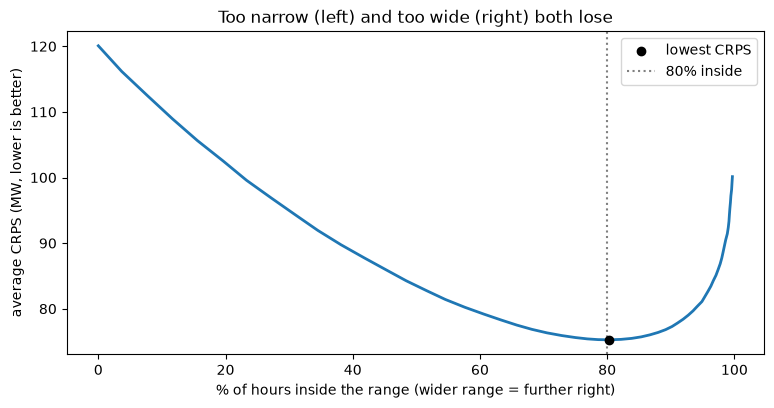

Best: about 80 % inside | CRPS 75.3 MW vs 120.1 MW with no range


In [4]:
rng = np.random.default_rng(5512)
fake_miss = rng.normal(0, 150, 20000)          # actual - expected, for 20,000 hours
k_values = np.arange(0, 3.01, 0.05)
avg_scores = []
inside_pcts = []
for k in k_values:
    half = k * 150
    avg_scores.append(np.mean(crps(fake_miss, -half, 0, half)))
    inside_pcts.append(100 * np.mean(np.abs(fake_miss) <= half))
best = int(np.argmin(avg_scores))

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(inside_pcts, avg_scores, linewidth=2)
ax.scatter([inside_pcts[best]], [avg_scores[best]], color="black", zorder=3, label="lowest CRPS")
ax.axvline(80, color="gray", linestyle=":", label="80% inside")
ax.set_xlabel("% of hours inside the range (wider range = further right)")
ax.set_ylabel("average CRPS (MW, lower is better)")
ax.set_title("Too narrow (left) and too wide (right) both lose")
ax.legend()
plt.show()
print("Best: about", round(inside_pcts[best]), "% inside | CRPS", round(avg_scores[best], 1), "MW vs", round(avg_scores[0], 1), "MW with no range")

The lowest score sits right around **80% inside**. You can't game the CRPS by lying about your range in either
direction: the best strategy is to be honest. That property has a name, a **proper** score.

In [5]:
QUANTILES = [0.1, 0.5, 0.9]      # low, expected, high


def judge(method, low, expected, high, actual):
    """Average CRPS over the test hours, plus how often the actual landed inside and how wide the range was."""
    actual = np.asarray(actual, dtype=float)
    low = np.asarray(low, dtype=float)
    high = np.asarray(high, dtype=float)
    inside = (actual >= low) & (actual <= high)
    return {"method": method,
            "inside range (%)": round(100 * float(np.mean(inside)), 1),     # aim: about 80
            "average width (MW)": round(float(np.mean(high - low))),
            "expected MAE (MW)": round(float(np.mean(np.abs(actual - np.asarray(expected)))), 1),
            "CRPS (MW)": round(float(np.mean(crps(actual, low, expected, high))), 1)}     # lower is better


ranges = {}          # method -> table of low, expected, high for every test hour
results = []

# Part 2 · Method 1: the random forest's spread (8 min)
A random forest is 100 trees, each trained on a different random sample of the training hours. Usually you **average**
the 100 guesses. Instead, line up all 100 guesses for an hour and read the **10th, 50th and 90th percentile**: low,
expected and high.

In [6]:
from sklearn.ensemble import RandomForestRegressor

started = time.time()
forest = RandomForestRegressor(n_estimators=100, min_samples_leaf=10, random_state=SEED, n_jobs=-1)
forest.fit(X_train, y_train)
guesses = []
for tree in forest.estimators_:
    guesses.append(tree.predict(X_test.values))         # each tree's guess for every test hour
guesses = np.array(guesses)                             # 100 rows (trees) x test hours
ranges["random forest spread"] = pd.DataFrame({"low": np.percentile(guesses, 10, axis=0),
                                               "expected": np.percentile(guesses, 50, axis=0),
                                               "high": np.percentile(guesses, 90, axis=0)}, index=X_test.index)
r = ranges["random forest spread"]
results.append(judge("random forest spread", r["low"], r["expected"], r["high"], y_test))
print("done in", round(time.time() - started), "seconds")
pd.DataFrame(results)

done in 5 seconds


,method,inside range (%),average width (MW),expected MAE (MW),CRPS (MW)
0,random forest spread,61.4,310,150.8,103.1


**Overconfident.** The trees **agree with each other** far more than the real load varies, so far fewer than 80% of
hours land inside. The spread of the trees measures how unsure the **forest** is about the average, not how much the
**load** bounces around that average. Give the forest more data and the trees agree even more, so the range shrinks,
while the real misses don't.

# Part 3 · Method 2: the quantile forest (8 min)
A **quantile regression forest** grows the same kind of trees. The one difference is what each leaf remembers:

| | Each leaf remembers | Prediction for a new hour |
|---|---|---|
| **Random forest** | the **average** load of the training hours that landed there | the average of 100 leaf averages |
| **Quantile forest** | **every real load** of the training hours that landed there | pool those real loads from all 100 trees, read off the 10th, 50th and 90th percentile |

So the quantile forest's range is the spread of **what really happened** in hours like this one: same hour, similar
temperature, similar load yesterday. You ask for the percentiles when you predict: `quantiles=[0.1, 0.5, 0.9]`.

In [7]:
from quantile_forest import RandomForestQuantileRegressor

started = time.time()
qrf = RandomForestQuantileRegressor(n_estimators=100, min_samples_leaf=10, random_state=SEED, n_jobs=-1)
qrf.fit(X_train, y_train)
q = qrf.predict(X_test, quantiles=QUANTILES)            # 3 columns: low, expected, high
ranges["quantile forest"] = pd.DataFrame({"low": q[:, 0], "expected": q[:, 1], "high": q[:, 2]}, index=X_test.index)
results.append(judge("quantile forest", q[:, 0], q[:, 1], q[:, 2], y_test))
print("done in", round(time.time() - started), "seconds")
pd.DataFrame(results)

done in 12 seconds


,method,inside range (%),average width (MW),expected MAE (MW),CRPS (MW)
0,random forest spread,61.4,310,150.8,103.1
1,quantile forest,77.8,457,153.5,98.9


# Part 4 · Compare (8 min)
Two more rows for reference: **no range** (the forest's average, Lab 5 style, so its CRPS is just its MAE) and a
**fixed range** (expected ± the same MW every hour, sized so 80% of a 2025 test run's misses fit inside: honest on
average, but never wider when the forecast is harder).

In [8]:
average = forest.predict(X_test)
results.append(judge("no range (forest average)", average, average, average, y_test))

# fixed range: a forest fit on 2023-2024 forecasts 2025 (hours it never saw); the 10th and 90th percentile of
# those misses are added to every test hour
early = X_train.index.tz_convert(LOCAL).year < TEST_YEAR - 1
helper = RandomForestRegressor(n_estimators=100, min_samples_leaf=10, random_state=SEED, n_jobs=-1)
helper.fit(X_train[early], y_train[early])
miss_2025 = y_train[~early].values - helper.predict(X_train[~early])
low_offset = np.percentile(miss_2025, 10)
high_offset = np.percentile(miss_2025, 90)
fixed = average
ranges["fixed range"] = pd.DataFrame({"low": fixed + low_offset, "expected": fixed, "high": fixed + high_offset}, index=X_test.index)
results.append(judge("fixed range (same MW every hour)", fixed + low_offset, fixed, fixed + high_offset, y_test))
scoreboard = pd.DataFrame(results).set_index("method").sort_values("CRPS (MW)")
scoreboard

,inside range (%),average width (MW),expected MAE (MW),CRPS (MW)
method,,,,
quantile forest,77.8,457,153.5,98.9
fixed range (same MW every hour),77.8,451,148.7,101.5
random forest spread,61.4,310,150.8,103.1
no range (forest average),0.0,0,148.7,148.7


**The hottest week of the test year**, both methods. A good band is **wider when the forecast is harder**.

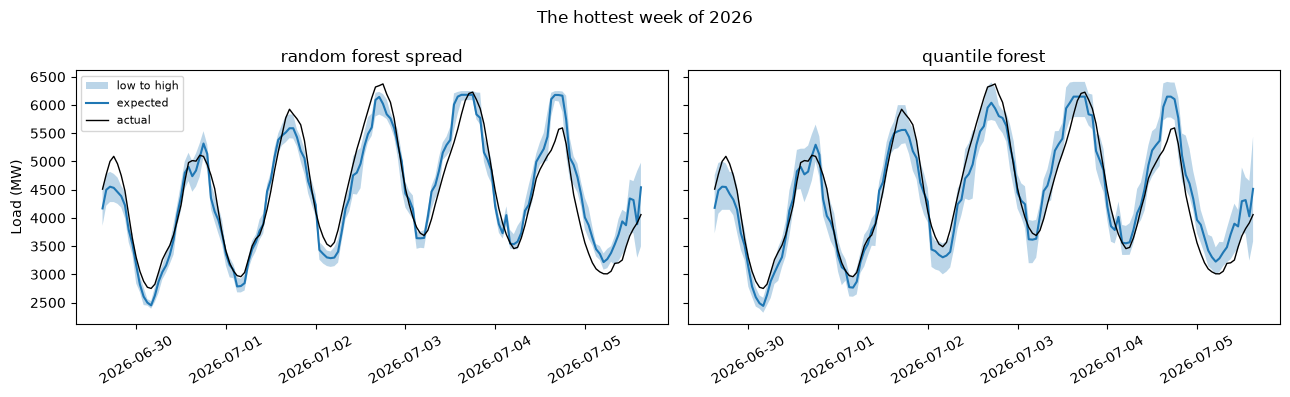

In [9]:
hottest = X_test["temp_f"].idxmax()
week_hours = X_test.loc[hottest - pd.Timedelta(days=3):hottest + pd.Timedelta(days=3)].index
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
methods = ["random forest spread", "quantile forest"]
for i in range(2):
    week = ranges[methods[i]].loc[week_hours]
    hours_local = week.index.tz_convert(LOCAL).tz_localize(None)
    axes[i].fill_between(hours_local, week["low"], week["high"], alpha=0.3, label="low to high")
    axes[i].plot(hours_local, week["expected"], label="expected")
    axes[i].plot(hours_local, y_test.loc[week_hours].values, color="black", linewidth=1, label="actual")
    axes[i].set_title(methods[i])
    axes[i].tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Load (MW)")
axes[0].legend(fontsize=8)
plt.suptitle("The hottest week of " + str(TEST_YEAR))
plt.tight_layout()
plt.show()

**Is the quantile forest honest at every hour of the day?**

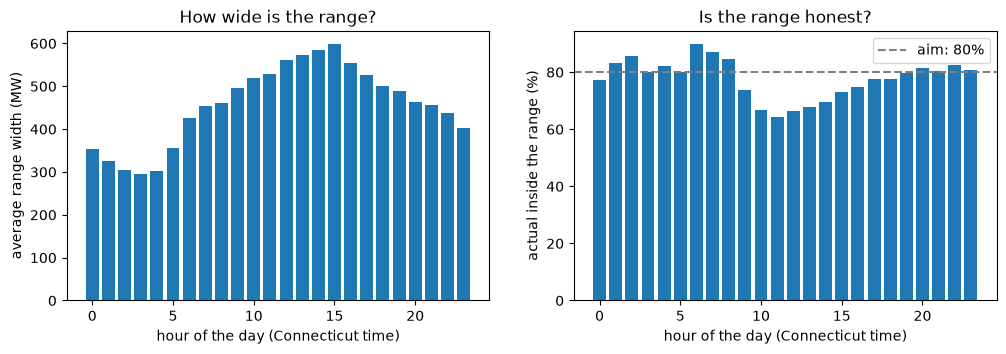

In [10]:
table = ranges["quantile forest"].copy()
table["actual"] = y_test.values
table["width"] = table["high"] - table["low"]
table["inside"] = (table["actual"] >= table["low"]) & (table["actual"] <= table["high"])
by_hour = table.groupby(table.index.tz_convert(LOCAL).hour)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(by_hour["width"].mean().index, by_hour["width"].mean().values)
ax[0].set_xlabel("hour of the day (Connecticut time)")
ax[0].set_ylabel("average range width (MW)")
ax[0].set_title("How wide is the range?")
ax[1].bar(by_hour["inside"].mean().index, 100 * by_hour["inside"].mean().values)
ax[1].axhline(80, color="gray", linestyle="--", label="aim: 80%")
ax[1].set_xlabel("hour of the day (Connecticut time)")
ax[1].set_ylabel("actual inside the range (%)")
ax[1].set_title("Is the range honest?")
ax[1].legend()
plt.show()

# Part 5 · The catch (8 min)
Everything above used the weather that **actually happened**. Production never has that. Feed the same quantile forest
the **HRRR forecast you'd really have had** (the 6A archive and its `hrrr_as_issued`, word for word) 1, 12 and 24
hours ahead, and watch the range.

In [11]:
archive = pd.read_csv(DATA + "bdl_hrrr_asissued_2023_2026.csv.gz", parse_dates=["init_utc", "hour_utc"])
READY_HOURS = 2


def hrrr_as_issued(target_hours, hours_ahead):
    """For each target hour: the HRRR forecast you would have had hours_ahead hours earlier, from the newest
    48-hour run that was ready by then. If that run is missing from the archive, the run before it."""
    issued = target_hours - pd.Timedelta(hours=hours_ahead)
    run = (issued - pd.Timedelta(hours=READY_HOURS)).floor("6h")
    table = pd.DataFrame(np.nan, index=target_hours, columns=WEATHER)
    for back in range(3):
        wanted = pd.DataFrame({"init_utc": run - pd.Timedelta(hours=6 * back), "hour_utc": target_hours})
        found = wanted.merge(archive, on=["init_utc", "hour_utc"], how="left")
        empty = table["temp_f"].isna().values
        table.loc[empty, WEATHER] = found.loc[empty, WEATHER].values
    return table


catch_hours = X_test.index[X_test.index <= archive["hour_utc"].max()]
catch = [judge("perfect weather", ranges["quantile forest"].loc[catch_hours, "low"],
               ranges["quantile forest"].loc[catch_hours, "expected"], ranges["quantile forest"].loc[catch_hours, "high"],
               y_test.loc[catch_hours])]
for ahead in [1, 12, 24]:
    X_hrrr = make_features(catch_hours, hrrr_as_issued(catch_hours, ahead), df["load_mw"])
    ok = X_hrrr[WEATHER].notna().all(axis=1)
    q_hrrr = qrf.predict(X_hrrr[ok], quantiles=QUANTILES)
    catch.append(judge("HRRR, " + str(ahead) + " h ahead", q_hrrr[:, 0], q_hrrr[:, 1], q_hrrr[:, 2], y_test.loc[X_hrrr[ok].index]))
pd.DataFrame(catch).set_index("method")

,inside range (%),average width (MW),expected MAE (MW),CRPS (MW)
method,,,,
perfect weather,77.8,457,153.5,98.9
"HRRR, 1 h ahead",75.5,457,167.4,108.6
"HRRR, 12 h ahead",73.9,460,174.0,113.3
"HRRR, 24 h ahead",72.8,458,177.3,116.1


**The range got no wider, but the misses got bigger** (the expected MAE column), so fewer actual loads land inside and
the CRPS climbs the further ahead you forecast. The quantile forest only learned **its own** mistakes, with perfect weather. Nobody told it
the weather can be wrong.

That's the job of **6C**: add the **weather's** uncertainty (the 8 HRRR runs from 6A Part 8) to the model's, ship the
combined range, and get on the Lab 6 leaderboard.

# Part 6 · Questions (5 min)
Answer in a sentence or two each. You'll paste them into **Submit Lab 6** at the end of 6C.

5. **Part 1:** Why did "too wide" score worse than no range at all, and why did "honest" win?
6. **Parts 2 and 3:** Which method came closer to 80% inside, and why is the random forest's spread overconfident?
7. **Part 4:** At which hours of the day is the quantile forest's range widest? Why would those hours be harder to forecast?
8. **Part 5:** How much did coverage drop with a 24-hour-old HRRR forecast instead of perfect weather? What's missing from the range?

*Your answers:*

---

**Next: 6C**, where the two kinds of uncertainty meet, and your range goes live.